# T3. What the regularizers do: action and parameter regularization, and the roles of their parts

Two regularizers act on different objects, and the paper's guidance is to choose each for what it does.

* The **action relative entropy** $\mathcal A$ (weight $\eta$) is a reward term on the *action law*. It holds the
  policy near an **action reference** $\rho$ and keeps the trajectory risk within $\mathrm{kl}(q\,\|\,q_\rho)\le\mathcal A$
  of the reference's risk (*Action regularization and trajectory risk*). It adds no curvature to the learning problem.
* The **parameter regularizer** $\mathcal H$ (strength $\kappa$) acts on the *law of the network's units*. It supplies
  the curvature that makes the population learning problem converge (*Fixed-stage population convergence*), and its
  bias is toward a **prior policy**, whose risk and utility the learner inherits (*Improvement over the prior policy*).

In the particle form of the flow (*The prior and the particle form of the flow*) the parameter regularizer splits into **roles**: a divergence
injects **noise** into every unit's parameters, a potential **pulls** them toward a reference, and a
faster-growing integrand limits their **spread**. Relative entropy alone ties noise and pull to one strength;
the general class unties them.

Part A shows the roles on the paper's solvable flow (numpy only, seconds). Parts B to E show the finite-network
counterparts on PPO in the wear-allowance problem at a deliberately low price, $m=0.03$, where the unregularized
optimum breaks down in a third of the episodes and a trusted incumbent rule exists. Each PPO run here trains for
one million steps (about 45 seconds); the paper used eight million and eight seeds. The notebook takes about twelve
minutes on one CPU core.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

import bpg
from bpg import Stage, Requirement, evaluate, sb3_policy, interpret, advise_regularizers, regularizer_effects, stopped_action_relative_entropy
from bpg.callbacks import ActionAnchor, ParameterAnchor, ParameterNoise, fit_actor_mean, set_log_std
from bpg.certificates import action_risk_bound, kl_upper_inverse
from bpg.convergence import FeatureConstants, curvature_budget
from bpg.examples.plateau import PlateauModel, simulate_particles, feature_bounds, chi
from bpg.examples.wear import WearModel, make_wear_env, IncumbentRule
from bpg.roles import RegularizerMix, stationary_spread, adam_stationary_spread

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## Which regularizer, for which condition

`advise_regularizers` recommends by condition and cites the result behind each recommendation. Here the
application has a trusted incumbent rule, a price we do not trust, and a finite network.

In [2]:
model = WearModel(); spec = model.spec(ubar=1.0)
low_price = Stage(m=0.03)
advice = advise_regularizers(spec, low_price, action_reference_trusted=True, price_trusted=False, incumbent_available=True,
                             starting_from_finite_network=True)
print(advice.explain())

Regularizers (recommended by condition; a regularizer creates no safety its target lacks):
  - action anchor: charge eta [log pi - log rho] toward the trusted action reference (eta > 0; current eta = 0)
      because the reference is trusted and the price or the model is not: the anchor keeps the trajectory risk within kl(q || q_rho) <= A of the reference's, which protects against a mispriced failure risk; it is not a substitute for the price  [paper, 'Action regularization and trajectory risk'; paper, the wear-allowance study; paper, 'Using the bounded barrier']
  - parameter anchor: weight decay kappa_p (theta - theta_0) toward the parameters theta_0 fitted to the incumbent (fit_actor_mean), covering every parameter that shapes the policy, the dispersion included (set_log_std)
      because an incumbent is in operation: the anchor holds the learner near it in parameter space with the curvature the action anchor lacks; a prior on the mean network alone leaves the dispersion free and t

## Part A. The roles on the solvable flow

The paper's solvable flow (in its online appendix) has one parameter per unit and a feature that is flat on
$[-1,1]$: units there do not affect the policy, so the value gradient vanishes. Starting from the **plateau
initial law** (all units in $[-1/2,1/2]$), unregularized transport cannot move. Only the regularizers can.

The particle form with relative entropy to $N(0,1)$ at strength $\kappa_1$ and the potential $x^2/2$ at strength
$\kappa_2$ moves each unit by
$$dx_i=\big[V_m'(c_n)\chi'(x_i)-(\kappa_1+\kappa_2)x_i\big]\,d\ell+\sqrt{2\kappa_1}\,dB_i .$$
Without noise ($\kappa_1=0$) the units collapse to the prior's center (*Collapse under a potential alone*). With noise they reach the
region where the feature acts. Under the combined pull the stationary spread is $\sqrt{\kappa_1/(\kappa_1+\kappa_2)}$.

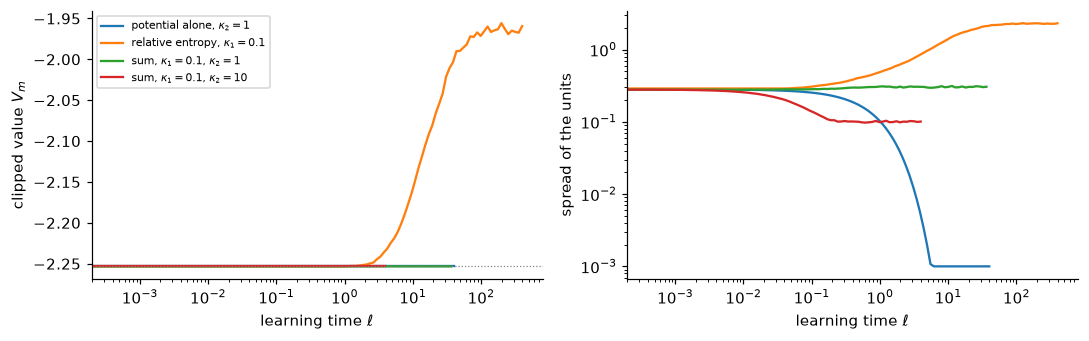

potential alone, $\kappa_2=1$      final V_m = -2.2533  spread = 0.000  predicted = 0.000
relative entropy, $\kappa_1=0.1$   final V_m = -1.9593  spread = 2.308  predicted = nan
sum, $\kappa_1=0.1$, $\kappa_2=1$  final V_m = -2.2533  spread = 0.305  predicted = 0.302
sum, $\kappa_1=0.1$, $\kappa_2=10$ final V_m = -2.2533  spread = 0.101  predicted = 0.100
plateau value: -2.2533


In [3]:
flow = PlateauModel()                      # eps = 0.2, m = 1, beta = 0.9, gamma = 1/2: the paper's parameters
plateau_value = flow.stats(0.0)["V_m"]
configs = {"potential alone, $\\kappa_2=1$": (0.0, 1.0), "relative entropy, $\\kappa_1=0.1$": (0.1, 0.0),
           "sum, $\\kappa_1=0.1$, $\\kappa_2=1$": (0.1, 1.0), "sum, $\\kappa_1=0.1$, $\\kappa_2=10$": (0.1, 10.0)}
runs = {name: simulate_particles(flow, k1, k2, n=2000, seed=1) for name, (k1, k2) in configs.items()}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for i, (name, r) in enumerate(runs.items()):
    axes[0].plot(r.times, r.V_m, color=f"C{i}", label=name)
    axes[1].plot(r.times, np.maximum(r.spread, 1e-3), color=f"C{i}")
axes[0].axhline(plateau_value, color="0.5", ls=":", lw=0.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("learning time $\\ell$"); axes[0].set_ylabel("clipped value $V_m$"); axes[0].legend(fontsize=7)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("learning time $\\ell$"); axes[1].set_ylabel("spread of the units")
plt.tight_layout(); plt.show()
for name, (k1, k2) in configs.items():
    r = runs[name]
    pred = stationary_spread(k1, k2) if k2 > 0 else float("nan")
    print(f"{name:34s} final V_m = {r.V_m[-1]:+.4f}  spread = {r.spread[-1]:.3f}  predicted = {pred:.3f}")
print(f"plateau value: {plateau_value:.4f}")

The potential alone collapses the units and never leaves the plateau value; relative entropy escapes; the sum
escapes only once its stationary spread is comparable to the plateau's width. Varying the noise at a fixed pull
shows the threshold.

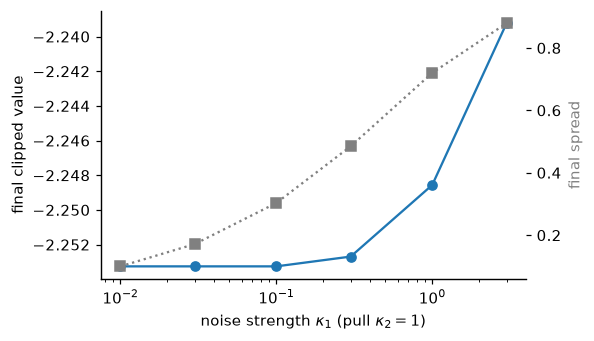

regularizer mix: kappa1 = 0.1 (divergence to N(x0, 1^2 I)), omega = 0, kappa2 = 1 (potential, curvature 1)
  noise: variance 0.2 per unit time per parameter
  pull: 1.1 per parameter toward the common center
  curvature supplied: 1.1
  stationary spread under a gradient pull: 0.3015 per parameter
  under Adam the measured spread was about sqrt(2) kappa1 = 0.141 instead (post-hoc explanation, not a result) [paper, the roles of the regularizers]
  [paper, 'The prior and the particle form of the flow']


In [4]:
k1s = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
flows = [simulate_particles(flow, k1, 1.0, n=1000, seed=2) for k1 in k1s]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.semilogx(k1s, [r.V_m[-1] for r in flows], "o-", label="final $V_m$")
ax.set_xlabel("noise strength $\\kappa_1$ (pull $\\kappa_2=1$)"); ax.set_ylabel("final clipped value")
ax2 = ax.twinx(); ax2.semilogx(k1s, [r.spread[-1] for r in flows], "s:", color="0.5"); ax2.set_ylabel("final spread", color="0.5")
plt.tight_layout(); plt.show()
print(RegularizerMix(kappa1=0.1, kappa2=1.0).explain())

## Convergence versus bias on the same flow

The convergence theorem certifies exponential convergence once the curvature $\kappa\lambda_W$ exceeds the deficit
$C_m+\eta C_{\mathcal A}$. For this flow $C_m=1940$, so the certified strength is $\kappa=2037$. The price of the
certificate is the bias toward the prior: the stronger the regularizer, the closer the minimizer is to the prior
policy. Relative entropy alone, at strengths from far below the threshold to the threshold itself:

In [5]:
cb = curvature_budget(FeatureConstants(**feature_bounds()), beta=0.9, m=1.0, ubar=1.0, kappa=2037.0, lambda_H=1.0)
print(cb.explain(), "\n")
th = np.linspace(-12, 12, 400001); c_prior = float(np.trapezoid(chi(th) * np.exp(-th ** 2 / 2) / np.sqrt(2 * np.pi), th))
prior_value = flow.stats(c_prior)["V_m"]
for kappa in (0.1, 1.0, 10.0, 2037.0):
    r = simulate_particles(flow, kappa, 0.0, n=2000, seed=3)
    print(f"kappa = {kappa:7g}: final V_m = {r.V_m[-1]:+.4f}, improvement over the prior policy = {r.V_m[-1] - prior_value:+.4f}")
print(f"prior policy N(0,1): V_m = {prior_value:+.4f}")

curvature deficit: C_m = 1940 (clipped value), eta C_A = 0 (action relative entropy)
curvature supplied by the parameter regularizer: 2037
budget Lambda_m = 97.03: certified; the objective gap decays like exp(-2 Lambda l), W2 like exp(-Lambda l)
certified threshold (margin 1.05): kappa >= 2037 at curvature 1 per unit strength; at that strength the minimizer lies close to the prior
time to shrink the objective gap by 1e-3: 0.0356
the deficit grows linearly with m + ubar and like (1-beta)^-3; set the strength for conditioning, not at the threshold [paper, 'Fixed-stage population convergence'; paper, 'The regularization bias is priced and detected'] 



kappa =     0.1: final V_m = -1.9719, improvement over the prior policy = +0.2555


kappa =       1: final V_m = -2.2161, improvement over the prior policy = +0.0113


kappa =      10: final V_m = -2.2248, improvement over the prior policy = +0.0025


kappa =    2037: final V_m = -2.2257, improvement over the prior policy = +0.0017
prior policy N(0,1): V_m = -2.2274


Every flow converges, far below the threshold too, and the improvement over the prior policy shrinks as $\kappa$
grows. At the certified strength the learner returns essentially the prior. The practical rule follows: set
$\kappa$ for conditioning, the smallest strength at which the optimizer behaves, not at the certified threshold.

## Part B. PPO helpers

The PPO settings are those of notebook T2. The **incumbent rule** runs at the rate $\min\{1,z/(3b)\}$ with a Gaussian
dispersion of $0.05$ in the rate: it breaks down in about one percent of the episodes. It serves as the action
reference $\rho$ (Part C) and, fitted into the actor, as the prior (Parts D and E).

In [6]:
def make_ppo(stage, seed=0, n_envs=32, log_std_init=-1.0):
    venv = DummyVecEnv([lambda: make_wear_env(stage, model) for _ in range(n_envs)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=1e9, gamma=1.0)
    return PPO("MlpPolicy", venv, seed=seed, n_steps=256, batch_size=1024, n_epochs=10, learning_rate=lambda p: 3e-4 * p, gamma=1.0,
               gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, policy_kwargs=dict(net_arch=[64, 64], log_std_init=log_std_init),
               device="cpu", verbose=0)


STEPS = 1_000_000
env = lambda: make_wear_env(low_price, model)
rule_mean = lambda z: np.minimum(1.0, np.maximum(z, 0.0) / 3.0)         # the incumbent's rate at reserve fraction z
RULE_STD = 0.05


def log_reference(obs, act):
    """log density of the incumbent rule at the actor's pre-clipping action (rate units)."""
    mu = rule_mean(np.asarray(obs)[:, 2]); a = np.asarray(act).reshape(-1)
    return -0.5 * ((a - mu) / RULE_STD) ** 2 - math.log(RULE_STD) - 0.5 * math.log(2 * math.pi)


def with_kl(ppo):
    """Policy that also returns the statewise relative entropy to the incumbent (closed form, pre-clipping Gaussians;
    by data processing this is an upper bound on the relative entropy of the clipped actions)."""
    def f(obs):
        with torch.no_grad():
            d = ppo.policy.get_distribution(torch.as_tensor(obs[None, :])).distribution
            mu, sd = float(d.mean.reshape(-1)[0]), float(d.stddev.reshape(-1)[0])
        m0 = float(rule_mean(obs[2]))
        kl = math.log(RULE_STD / sd) + (sd ** 2 + (mu - m0) ** 2) / (2 * RULE_STD ** 2) - 0.5
        return np.array([mu + sd * np.random.standard_normal()], dtype=np.float32), kl
    return f


def assess(ppo, seed, n=10_000):
    e = evaluate(env, sb3_policy(ppo), n, spec=spec, stage=low_price, seed=seed, T=19)
    A = stopped_action_relative_entropy(env, with_kl(ppo), 1000, beta=spec.beta, seed=seed + 1)["A"]
    return e, A


rule_eval = evaluate(env, IncumbentRule(span=3.0, std=0.1, seed=0), 20_000, spec=spec, stage=low_price, seed=7, T=19)
q_ref = rule_eval.q_beta
print(f"incumbent rule: q_beta = {q_ref:.4f}, U = {rule_eval.U:.3f}")

incumbent rule: q_beta = 0.0103, U = 2.719


## Part C. The action anchor

`ActionAnchor` charges $\eta[\log\pi(a\mid y)-\log\rho(a\mid y)]$ at every decision up to and including the
failing one, the sample form of $\mathcal A$. At this low price the unanchored learner heads for the risky optimum;
the anchor holds it near the incumbent.

In [7]:
action_runs = {}
for eta in (0.0, 0.1, 1.0):
    ppo = make_ppo(low_price, seed=0)
    ppo.learn(STEPS, callback=[ActionAnchor(eta, log_reference)] if eta > 0 else [])
    action_runs[eta] = assess(ppo, seed=20)
    e, A = action_runs[eta]
    b = action_risk_bound(A, q_ref, spec.beta)
    print(f"eta = {eta:<4g}: q_beta = {e.q_beta:.4f}, U = {e.U:.3f}, A = {A:9.3f}, kl bound: q in [{b.inputs['lower']:.4f}, {b.value:.4f}]"
          f" ({'informative' if b.informative else 'uninformative'})")

eta = 0   : q_beta = 0.5894, U = 5.350, A =  2291.318, kl bound: q in [0.0000, 1.0000] (uninformative)


eta = 0.1 : q_beta = 0.0187, U = 2.775, A =     3.017, kl bound: q in [0.0000, 0.7747] (informative)


eta = 1   : q_beta = 0.0101, U = 2.684, A =     0.373, kl bound: q in [0.0000, 0.1839] (informative)


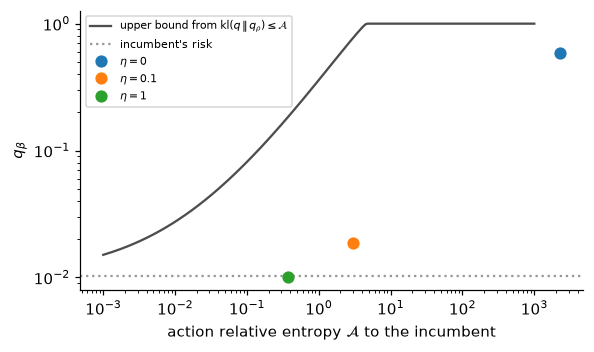

In [8]:
A_grid = np.logspace(-3, 3, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.loglog(A_grid, [kl_upper_inverse(q_ref, a) for a in A_grid], color="0.3", label="upper bound from $\\mathrm{kl}(q\\,\\|\\,q_\\rho)\\leq\\mathcal{A}$")
ax.axhline(q_ref, color="0.6", ls=":", label="incumbent's risk")
for eta, (e, A) in action_runs.items():
    ax.plot(max(A, 1e-3), e.q_beta, "o", ms=7, label=f"$\\eta={eta:g}$")
ax.set_xlabel("action relative entropy $\\mathcal{A}$ to the incumbent"); ax.set_ylabel("$q_\\beta$"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

The bound holds in every run and is informative only when $\mathcal A$ is small, that is, when the learner stays
close to the incumbent and gains little. The anchor protects against a mispriced failure risk when the reference
is trusted; at a correct price it costs utility, and it is not a substitute for the price.

## Part D. The parameter anchor: the prior is a policy

A finite network carries the pull part of a Gaussian prior: weight decay toward parameters $\theta_0$
(`ParameterAnchor`; the paper's *The Gaussian prior as entropy, weight decay, and a policy*). We fit the actor's mean to the incumbent rule (`fit_actor_mean`) and set its
dispersion to the incumbent's (`set_log_std`): the actor at $\theta_0$ is then the **prior policy**. The learner
inherits the prior policy's risk and utility, so we evaluate it as a candidate before training.

The prior must cover every parameter that shapes the policy. Anchoring the mean network alone leaves the
dispersion free, and the learner can escape through that one parameter (the paper's parameter-anchor study).

In [9]:
obs_fit = np.column_stack([np.random.default_rng(0).uniform(-1, 1, 20_000), np.ones(20_000),
                           np.random.default_rng(1).uniform(0, 1, 20_000)]).astype(np.float32)


def prior_ppo(seed=0):
    ppo = make_ppo(low_price, seed=seed)
    mse = fit_actor_mean(ppo, lambda o: rule_mean(o[:, 2]).reshape(-1, 1), obs_fit, steps=3000, lr=3e-3, seed=seed)
    set_log_std(ppo, math.log(RULE_STD))
    return ppo, mse


ppo0, mse = prior_ppo()
prior_eval, prior_A = assess(ppo0, seed=30)
print(f"fit error {mse:.2e}; prior policy: q_beta = {prior_eval.q_beta:.4f}, U = {prior_eval.U:.3f}, A = {prior_A:.3f}")

param_runs = {}
for label, kappa_p, logstd in (("control, kappa_p = 0", 0.0, True), ("anchor, kappa_p = 10", 10.0, True),
                               ("anchor, kappa_p = 100", 100.0, True), ("mean-only anchor, kappa_p = 100", 100.0, False)):
    ppo, _ = prior_ppo()
    anchor = ParameterAnchor(ppo, kappa_p, include_log_std=logstd).install()
    ppo.learn(STEPS)
    e, A = assess(ppo, seed=40)
    param_runs[label] = (e, A, anchor)
    print(f"{label:32s} q_beta = {e.q_beta:.4f}, U = {e.U:.3f}, A = {A:9.3f}, ||theta - theta_0|| = {anchor.distance():.4f}, "
          f"dispersion {anchor.effects_inputs()['dispersion_prior']:.3f} -> {anchor.dispersion():.3f}")

fit error 1.31e-06; prior policy: q_beta = 0.0102, U = 2.741, A = 0.006


control, kappa_p = 0             q_beta = 0.2665, U = 3.925, A =   126.584, ||theta - theta_0|| = 0.8180, dispersion 0.050 -> 0.041


anchor, kappa_p = 10             q_beta = 0.0393, U = 3.067, A =     7.379, ||theta - theta_0|| = 0.0333, dispersion 0.050 -> 0.050


anchor, kappa_p = 100            q_beta = 0.0113, U = 2.766, A =     0.088, ||theta - theta_0|| = 0.0508, dispersion 0.050 -> 0.050


mean-only anchor, kappa_p = 100  q_beta = 0.0129, U = 2.819, A =     0.692, ||theta - theta_0|| = 0.0498, dispersion 0.050 -> 0.045


In [10]:
cand = lambda e: dict(q_beta=e.q_beta, U=e.U, q_se=e.q_se, U_se=e.U_se, V_m=e.V_m, V_se=e.V_m_se)
prior_c = cand(prior_eval)
for label in ("anchor, kappa_p = 100", "mean-only anchor, kappa_p = 100"):
    e, A, anchor = param_runs[label]
    eff = regularizer_effects(spec, low_price.with_(kappa=anchor.kappa_p), cand(e), prior_policy=prior_c, **anchor.effects_inputs())
    print(label); print(eff.explain(), "\n")
path = [dict(kappa=k, q_beta=param_runs[l][0].q_beta, U=param_runs[l][0].U) for l, k in
        (("control, kappa_p = 0", 0.0), ("anchor, kappa_p = 10", 10.0), ("anchor, kappa_p = 100", 100.0))]
print(regularizer_effects(spec, low_price.with_(kappa=10.0), cand(param_runs["anchor, kappa_p = 10"][0]), path=path).explain())

anchor, kappa_p = 100
Regularizer effects on the candidate:
  - parameter anchor (kappa = 100): ||theta - theta_0|| = 0.05077; action dispersion 0.05 -> 0.05 [paper, 'The Gaussian prior as entropy, weight decay, and a policy'; paper, the parameter-anchor study]
  - inheritance: candidate minus prior policy, q_beta +0.0011 (se 0.0015), U +0.0248 (se 0.026); the candidate sits at the prior policy within sampling error: the regularization returned the prior (no learning gain) [paper, 'The prior and the particle form of the flow'; paper, 'Improvement over the prior policy'] 

mean-only anchor, kappa_p = 100
Regularizer effects on the candidate:
  - parameter anchor (kappa = 100): ||theta - theta_0|| = 0.04985; action dispersion 0.05 -> 0.0453 (not anchored) [paper, 'The Gaussian prior as entropy, weight decay, and a policy'; paper, the parameter-anchor study]
  - inheritance: candidate minus prior policy, q_beta +0.0027 (se 0.0015), U +0.07771 (se 0.026); the candidate has moved from the p

The anchor moves the learner back from the control toward the prior policy as $\kappa_p$ grows, in risk and utility
together; at the strongest anchor the candidate sits at the prior policy. In this one-million-step run the free
dispersion of the mean-only anchor moved only a little. In the paper's study (eight million steps, starting from the
learner's wider default dispersion) it grew from 0.37 to 7.5 while the mean network stayed at $\theta_0$, and the
policy became bang-bang with a third of the episodes breaking down. The flag in `regularizer_effects` fires when an
unanchored dispersion moves by more than half; whether it does depends on the run, which is why the prior should
cover the dispersion in the first place.

## Part E. The roles on PPO: pull and noise

The finite-network counterpart of the entropy term is Gaussian noise of variance $2\kappa_1$ times the learning
rate after each optimizer step (`ParameterNoise`). Under a plain gradient pull $\kappa_2$ the per-parameter
spread would converge to $\sqrt{\kappa_1/(\kappa_1+\kappa_2)}$. The paper measured, with Adam, a spread proportional to
$\kappa_1$ instead (about $\sqrt2\,\kappa_1$): Adam normalizes the pull to a step of fixed size. The roles survived,
the formula did not. Here: the anchor $\kappa_2=10$ with noise $\kappa_1\in\{0.01,0.1\}$, and noise alone.

In [11]:
noise_runs = {0.0: (param_runs["anchor, kappa_p = 10"][0], param_runs["anchor, kappa_p = 10"][2].spread())}
for k1, k2 in ((0.01, 10.0), (0.1, 10.0), (0.1, 0.0)):
    ppo, _ = prior_ppo()
    anchor = ParameterAnchor(ppo, k2).install()
    noise = ParameterNoise(ppo, k1, seed=0).install()
    ppo.learn(STEPS)
    e, A = assess(ppo, seed=50)
    noise_runs[(k1, k2)] = (e, noise.spread())
    print(f"kappa1 = {k1:<5g} kappa2 = {k2:<4g}: q_beta = {e.q_beta:.4f}, U = {e.U:.3f}, A = {A:10.3f}, spread = {noise.spread():.4f} "
          f"(gradient-pull formula {stationary_spread(k1, k2) if k2 else float('nan'):.4f}, Adam sqrt(2) kappa1 = {adam_stationary_spread(k1):.4f})")
e, spread = noise_runs[(0.1, 0.0)]
print("\n" + regularizer_effects(spec, low_price, cand(e), noise_kappa1=0.1, anchor_kappa2=0.0, spread=spread, prior_policy=prior_c).explain())

kappa1 = 0.01  kappa2 = 10  : q_beta = 0.0373, U = 2.967, A =      3.617, spread = 0.0115 (gradient-pull formula 0.0316, Adam sqrt(2) kappa1 = 0.0141)


kappa1 = 0.1   kappa2 = 10  : q_beta = 0.1095, U = 3.753, A =     82.118, spread = 0.1193 (gradient-pull formula 0.0995, Adam sqrt(2) kappa1 = 0.1414)


kappa1 = 0.1   kappa2 = 0   : q_beta = 0.5152, U = 5.266, A =   3885.268, spread = 0.5341 (gradient-pull formula nan, Adam sqrt(2) kappa1 = 0.1414)

Regularizer effects on the candidate:
  - parameter noise (kappa1 = 0.1, no pull): per-parameter spread 0.534; under Adam the paper measured about sqrt(2) kappa1 = 0.141 [paper, the roles of the regularizers]
  - inheritance: candidate minus prior policy, q_beta +0.505 (se 0.0051), U +2.525 (se 0.035); the candidate has moved from the prior policy toward the unregularized optimum [paper, 'The prior and the particle form of the flow'; paper, 'Improvement over the prior policy']
  flag: noise without a pull abandons the prior: in the paper's study it acted as exploration, raised the clipped objective and moved the policy far from the incumbent


The pull $\kappa_2$ sets where the units are held and the noise $\kappa_1$ how far they spread. Noise without a pull
abandons the prior and acts as exploration. Treat $\kappa_1$ as a knob to vary and measure, not one to set from the formula.

## Joint use

With both regularizers the action term pulls the action law toward $\rho$ and the parameter term pulls the unit law
toward the prior policy. Here the two targets coincide by construction (the prior is the incumbent with the
incumbent's dispersion), which is what the centering construction does in the population setting. Their biases add
in every certificate as $\mathcal R=\eta\mathcal A+\kappa\mathcal H$, and the action term adds $\eta C_{\mathcal A}$ to
the curvature the parameter term must supply.

In [12]:
ppo, _ = prior_ppo()
anchor = ParameterAnchor(ppo, 10.0).install()
ppo.learn(STEPS, callback=[ActionAnchor(0.1, log_reference)])
e, A = assess(ppo, seed=60)
joint = regularizer_effects(spec, Stage(m=0.03, eta=0.1, kappa=10.0), cand(e), action_entropy=A, reference_risk=q_ref,
                            prior_policy=prior_c, centered=True, **anchor.effects_inputs())
print(f"joint: q_beta = {e.q_beta:.4f}, U = {e.U:.3f}, A = {A:.3f}\n"); print(joint.explain())

joint: q_beta = 0.0123, U = 2.800, A = 0.305

Regularizer effects on the candidate:
  - action anchor (eta = 0.1): A = 0.3045 to the reference (risk 0.01025); kl(q || q_rho) <= A gives q in [6.379e-63, 0.1609], informative; the candidate's q_beta = 0.0123 lies inside the interval [paper, 'Action regularization and trajectory risk']
  - parameter anchor (kappa = 10): ||theta - theta_0|| = 0.02376; action dispersion 0.05 -> 0.05 [paper, 'The Gaussian prior as entropy, weight decay, and a policy'; paper, the parameter-anchor study]
  - inheritance: candidate minus prior policy, q_beta +0.0021 (se 0.0015), U +0.05858 (se 0.026); the candidate has moved from the prior policy toward the unregularized optimum [paper, 'The prior and the particle form of the flow'; paper, 'Improvement over the prior policy']
  - joint effect: both anchors act: the action term pulls the action law toward rho, the parameter term pulls the unit law toward pi_Gamma; under the centering construction these coincide, 

## Summary

| Regularizer | Acts on | What it does | Toolbox |
|---|---|---|---|
| action relative entropy $\eta\mathcal A$ | the action law | holds the policy near $\rho$; risk within $\mathrm{kl}\le\mathcal A$ of $\rho$'s; no curvature | `ActionAnchor` |
| prior's potential / anchor (pull) | the unit law | holds the units near $\theta_0$; supplies curvature; the learner inherits the prior policy | `ParameterAnchor` |
| entropy of relative entropy (noise) | the unit law | spreads the units; lets them leave flat regions; exploration without a pull | `ParameterNoise` |
| faster-growing integrand (spread) | the unit law | limits crowding relative to the prior; needs a density | population flow only |

* Specify the prior as a policy, through every parameter that shapes it, and evaluate it before training.
* Set the strengths for conditioning, not at the certified threshold.
* Validate the learned policy: a harmful bias shows up as a failed certificate or validation, never as a passed one.

Next: **notebook T4** goes through validation and the report in detail.